# High Tunnel harvest analysis

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "02_high_tunnel":
    ROOT = ROOT.parent.parent
if not (ROOT / "batches").is_dir():
    raise FileNotFoundError("Open this notebook from the project folder.")
BATCH_DIR = ROOT / "batches/02_high_tunnel"
os.chdir(BATCH_DIR)
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## Workbook

Weights in grams.

In [2]:
from pathlib import Path

import re

import pandas as pd

workbook = ROOT / "data/processed/Harvest 2026 Sapkota lab CLEANED.xlsx"

## High Tunnel harvests

In [3]:
harvest_sheets = [
    "HT_01_First_2026-07-13",
    "HT_02_Second_2026-07-20",
    "HT_03_Third_2026-07-27",
    "HT_04_Fourth_2026-08-03",
    "HT_05_Fifth_2026-08-10",
    "HT_06_Sixth_2026-08-18",
    "HT_07_Seventh_2026-08-19_Nam",
]

sheet_to_harvest = {
    "HT_01_First_2026-07-13": "First",
    "HT_02_Second_2026-07-20": "Second",
    "HT_03_Third_2026-07-27": "Third",
    "HT_04_Fourth_2026-08-03": "Fourth",
    "HT_05_Fifth_2026-08-10": "Fifth",
    "HT_06_Sixth_2026-08-18": "Sixth",
    "HT_07_Seventh_2026-08-19_Nam": "Seventh",
}

all_harvests = []

for sheet in harvest_sheets:
    data = pd.read_excel(workbook, sheet_name=sheet)
    data = data.dropna(how="all").copy()
    data.columns = data.columns.str.strip()
    data["Source Sheet"] = sheet
    all_harvests.append(data)

harvest_master = pd.concat(all_harvests, ignore_index=True)

harvest_master = harvest_master[harvest_master["Genotypes"].notna()].copy()

for column in ["Genotypes", "Location", "Harvest"]:
    harvest_master[column] = (
        harvest_master[column]
        .astype("string")
        .str.strip()
    )

## Genotype labels and missing values

In [4]:
harvest_master["Genotype_raw"] = harvest_master["Genotypes"]

def clean_genotype(name):
    """Turn UKY-26-015 / UKYT 26-032 / UKyt 26-024 into UKYT-26-015 etc."""
    if pd.isna(name):
        return name
    text = str(name).strip()
    uk_line = re.match(
        r"(?i)^uky[t]?\s*-?\s*(\d{2})\s*-?\s*(\d{1,3})$",
        text,
    )
    if uk_line:
        year, number = uk_line.group(1), int(uk_line.group(2))
        return f"UKYT-{year}-{number:03d}"
    return text

harvest_master["Genotypes"] = harvest_master["Genotype_raw"].map(clean_genotype)

harvest_master["Location"] = (
    harvest_master["Location"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

harvest_master["Location"] = harvest_master["Location"].replace(
    {r"(?i)^high\s*tunnel$": "High tunnel"},
    regex=True,
)

harvest_master.loc[harvest_master["Location"].isna(), "Location"] = "High tunnel"

harvest_master["Date of harvest"] = pd.to_datetime(
    harvest_master["Date of harvest"],
    errors="coerce",
)

numeric_columns = [
    "Grade 1 Marketable (weight)",
    "Grade 1 Marketable (counts)",
    "Grade 2 Marketable (weight)",
    "Grade 2 Marketable (counts)",
    "Unmarketables (weight)",
    "Unmarketables (counts)",
]

for column in numeric_columns:
    harvest_master[column] = pd.to_numeric(
        harvest_master[column],
        errors="coerce",
    )

harvest_master["Harvest"] = harvest_master["Harvest"].fillna(
    harvest_master["Source Sheet"].map(sheet_to_harvest)
)

## Row totals

Marketable weight = Grade 1 + Grade 2. Total weight adds unmarketable weight. Rows with no measured components remain blank.

In [5]:
harvest_master["Total Marketable Weight"] = harvest_master[
    ["Grade 1 Marketable (weight)", "Grade 2 Marketable (weight)"]
].sum(axis=1, min_count=1)

harvest_master["Total Marketable Count"] = harvest_master[
    ["Grade 1 Marketable (counts)", "Grade 2 Marketable (counts)"]
].sum(axis=1, min_count=1)

harvest_master["Total Harvest Weight"] = harvest_master[
    ["Total Marketable Weight", "Unmarketables (weight)"]
].sum(axis=1, min_count=1)

harvest_master["Marketable Percentage"] = (
    harvest_master["Total Marketable Weight"]
    / harvest_master["Total Harvest Weight"]
    * 100
)

harvest_master["Average Marketable Weight Per Count"] = (
    harvest_master["Total Marketable Weight"]
    / harvest_master["Total Marketable Count"]
)

column_order = [
    "SN",
    "Genotype_raw",
    "Genotypes",
    "Location",
    "Date of harvest",
    "Harvest",
    "Source Sheet",
    "Grade 1 Marketable (weight)",
    "Grade 1 Marketable (counts)",
    "Grade 2 Marketable (weight)",
    "Grade 2 Marketable (counts)",
    "Unmarketables (weight)",
    "Unmarketables (counts)",
    "Total Marketable Weight",
    "Total Marketable Count",
    "Total Harvest Weight",
    "Marketable Percentage",
    "Average Marketable Weight Per Count",
]

harvest_master = harvest_master[column_order]

harvest_master.to_csv("harvest_master.csv", index=False)

changed = harvest_master[
    harvest_master["Genotype_raw"] != harvest_master["Genotypes"]
][["Genotype_raw", "Genotypes", "Source Sheet"]].drop_duplicates()

## Genotype summary

In [6]:
harvest_order = [
    "HT_01_First_2026-07-13",
    "HT_02_Second_2026-07-20",
    "HT_03_Third_2026-07-27",
    "HT_04_Fourth_2026-08-03",
    "HT_05_Fifth_2026-08-10",
    "HT_06_Sixth_2026-08-18",
    "HT_07_Seventh_2026-08-19_Nam",
]

has_weight = harvest_master["Total Harvest Weight"].notna()

by_geno = harvest_master.groupby("Genotypes", dropna=False)

measured = harvest_master.loc[has_weight]

row_total_count = harvest_master[
    ["Total Marketable Count", "Unmarketables (counts)"]
].sum(axis=1, min_count=1)

genotype_summary = pd.DataFrame(
    {
        "n_rows": by_geno.size(),
        "n_with_weight": measured.groupby("Genotypes").size(),
        "n_harvests_with_weight": measured.groupby("Genotypes")[
            "Source Sheet"
        ].nunique(),
        "total_grade1_weight": by_geno["Grade 1 Marketable (weight)"].sum(
            min_count=1
        ),
        "total_grade2_weight": by_geno["Grade 2 Marketable (weight)"].sum(
            min_count=1
        ),
        "total_marketable_weight": by_geno["Total Marketable Weight"].sum(
            min_count=1
        ),
        "total_marketable_count": by_geno["Total Marketable Count"].sum(
            min_count=1
        ),
        "total_unmarketable_weight": by_geno["Unmarketables (weight)"].sum(
            min_count=1
        ),
        "total_unmarketable_count": by_geno["Unmarketables (counts)"].sum(
            min_count=1
        ),
        "total_weight": by_geno["Total Harvest Weight"].sum(min_count=1),
        "total_count": row_total_count.groupby(
            harvest_master["Genotypes"]
        ).sum(min_count=1),
    }
)

genotype_summary["n_with_weight"] = (
    genotype_summary["n_with_weight"].fillna(0).astype(int)
)

genotype_summary["n_harvests_with_weight"] = (
    genotype_summary["n_harvests_with_weight"].fillna(0).astype(int)
)

genotype_summary["marketable_percentage"] = (
    genotype_summary["total_marketable_weight"]
    / genotype_summary["total_weight"]
    * 100
)

genotype_summary["mean_weight_per_count"] = (
    genotype_summary["total_weight"]
    / genotype_summary["total_count"]
)

## Harvest coverage

Mean yield per harvest uses the number of harvests with a recorded weight.

In [7]:
genotype_summary["mean_weight_per_harvest"] = (
    genotype_summary["total_weight"]
    / genotype_summary["n_harvests_with_weight"].replace(0, pd.NA)
)

genotype_summary["mean_count_per_harvest"] = (
    genotype_summary["total_count"]
    / genotype_summary["n_harvests_with_weight"].replace(0, pd.NA)
)

genotype_summary = genotype_summary.reset_index()

genotype_summary = genotype_summary.sort_values(
    ["total_weight", "Genotypes"],
    ascending=[False, True],
    na_position="last",
)

genotype_summary["rank_by_total_weight"] = range(
    1, len(genotype_summary) + 1
)

by_per_harvest = genotype_summary.sort_values(
    ["mean_weight_per_harvest", "Genotypes"],
    ascending=[False, True],
    na_position="last",
).copy()

by_per_harvest["rank_by_mean_per_harvest"] = range(1, len(by_per_harvest) + 1)

rank_map = by_per_harvest.set_index("Genotypes")["rank_by_mean_per_harvest"]

genotype_summary["rank_by_mean_per_harvest"] = genotype_summary["Genotypes"].map(
    rank_map
)

summary_columns = [
    "rank_by_total_weight",
    "rank_by_mean_per_harvest",
    "Genotypes",
    "n_rows",
    "n_with_weight",
    "n_harvests_with_weight",
    "total_grade1_weight",
    "total_grade2_weight",
    "total_marketable_weight",
    "total_marketable_count",
    "total_unmarketable_weight",
    "total_unmarketable_count",
    "total_weight",
    "total_count",
    "mean_weight_per_harvest",
    "mean_count_per_harvest",
    "marketable_percentage",
    "mean_weight_per_count",
]

genotype_summary = genotype_summary[summary_columns]

genotype_summary.to_csv("genotype_summary.csv", index=False)

coverage = (
    measured.pivot_table(
        index="Genotypes",
        columns="Source Sheet",
        values="Total Harvest Weight",
        aggfunc="sum",
    )
    .reindex(columns=harvest_order)
    .reset_index()
)

coverage.to_csv("genotype_harvest_coverage.csv", index=False)

## Rankings

In [8]:
top15_total = genotype_summary.head(15).copy()

top15_total.to_csv("top15_total_weight.csv", index=False)

top15_per_harvest = by_per_harvest.head(15).copy()

top15_per_harvest.to_csv("top15_mean_weight_per_harvest.csv", index=False)

comparable = genotype_summary[
    genotype_summary["n_harvests_with_weight"] >= 5
].copy()

comparable = comparable.sort_values(
    ["mean_weight_per_harvest", "Genotypes"],
    ascending=[False, True],
    na_position="last",
).reset_index(drop=True)

comparable["rank_among_ge5_by_mean_per_harvest"] = range(1, len(comparable) + 1)

top15_ge5_per = comparable.head(15)

top15_ge5_per.to_csv("top15_mean_per_harvest_ge5.csv", index=False)

by_count = genotype_summary.sort_values(
    ["total_count", "Genotypes"],
    ascending=[False, True],
    na_position="last",
).copy()

by_count["rank_by_total_count"] = range(1, len(by_count) + 1)

top15_count = by_count.head(15)

top15_count.to_csv("top15_total_count.csv", index=False)

by_mkt = comparable.sort_values(
    ["marketable_percentage", "Genotypes"],
    ascending=[False, True],
    na_position="last",
).reset_index(drop=True)

by_mkt["rank_among_ge5_by_marketable_pct"] = range(1, len(by_mkt) + 1)

top15_mkt = by_mkt.head(15)

top15_mkt.to_csv("top15_marketable_pct_ge5.csv", index=False)

genotype_summary["weight_per_count_class"] = pd.cut(
    genotype_summary["mean_weight_per_count"],
    bins=[0, 50, 150, float("inf")],
    labels=[
        "mean wt/count <50 g",
        "mean wt/count 50–150 g",
        "mean wt/count >150 g",
    ],
)

genotype_summary.to_csv("genotype_summary.csv", index=False)

size_counts = (
    genotype_summary["weight_per_count_class"]
    .value_counts()
    .reindex(
        [
            "mean wt/count <50 g",
            "mean wt/count 50–150 g",
            "mean wt/count >150 g",
        ]
    )
)

grade_top = top15_total[
    [
        "Genotypes",
        "total_grade1_weight",
        "total_grade2_weight",
        "total_unmarketable_weight",
        "total_weight",
    ]
].copy()

for col in [
    "total_grade1_weight",
    "total_grade2_weight",
    "total_unmarketable_weight",
]:
    grade_top[col] = grade_top[col].fillna(0)

grade_top.to_csv("top15_grade_composition.csv", index=False)

size_tops = {}

In [9]:
for label in [
    "mean wt/count <50 g",
    "mean wt/count 50–150 g",
    "mean wt/count >150 g",
]:
    sub = genotype_summary[
        (genotype_summary["weight_per_count_class"] == label)
        & (genotype_summary["n_harvests_with_weight"] >= 3)
    ].sort_values("mean_weight_per_harvest", ascending=False)
    size_tops[label] = sub.head(8)
    safe = label.replace(" ", "_").replace("/", "_").replace("–", "-")
    sub.head(8).to_csv(f"top8_mean_per_harvest_{safe}.csv", index=False)

## Yield and grade composition

In [10]:
import matplotlib.pyplot as plt

figures = Path("figures")

figures.mkdir(exist_ok=True)

harvest_labels = {
    "HT_01_First_2026-07-13": "Harvest 1\n(First)",
    "HT_02_Second_2026-07-20": "Harvest 2\n(Second)",
    "HT_03_Third_2026-07-27": "Harvest 3\n(Third)",
    "HT_04_Fourth_2026-08-03": "Harvest 4\n(Fourth)",
    "HT_05_Fifth_2026-08-10": "Harvest 5\n(Fifth)",
    "HT_06_Sixth_2026-08-18": "Harvest 6\n(Sixth)",
    "HT_07_Seventh_2026-08-19_Nam": "Harvest 7\n(Seventh)",
}

harvest_short = [harvest_labels[s] for s in harvest_order]

def plot_top15_bars(df, value_col, path, title, xlabel, divide_by_1000=True):
    plot_df = df.sort_values(value_col, ascending=True)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    vals = plot_df[value_col] / 1000 if divide_by_1000 else plot_df[value_col]
    ax.barh(plot_df["Genotypes"], vals, color="#0033A0")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for y, v in enumerate(vals):
        label = f"{v:.2f}" if divide_by_1000 else f"{v:.0f}"
        ax.text(v + (0.05 if divide_by_1000 else max(vals) * 0.01), y, label,
                va="center", fontsize=8, color="#4a4a4a")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

plot_top15_bars(
    top15_total,
    "total_weight",
    figures / "fig1_top15_total_weight.png",
    "Top 15 by total weight (high tunnel)",
    "Total weight (kg)",
)

plot_top15_bars(
    top15_per_harvest,
    "mean_weight_per_harvest",
    figures / "fig2_top15_mean_per_harvest.png",
    "Top 15 by mean weight per harvest",
    "Mean weight per harvest (kg)",
)

plot_top15_bars(
    top15_ge5_per,
    "mean_weight_per_harvest",
    figures / "fig3_top15_mean_per_harvest_ge5.png",
    "Top 15 by mean per harvest (≥5 harvests recorded)",
    "Mean weight per harvest (kg)",
)

plot_top15_bars(
    top15_count,
    "total_count",
    figures / "fig7_top15_total_count.png",
    "Top 15 by total count (high tunnel)",
    "Total count",
    divide_by_1000=False,
)

In [11]:
def plot_harvest_lines(genotypes, path, title):
    """Line chart: each genotype's weight at each harvest."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    x = list(range(len(harvest_order)))
    for geno in genotypes:
        row = coverage.loc[coverage["Genotypes"] == geno]
        if row.empty:
            continue
        y = []
        for sheet in harvest_order:
            val = row.iloc[0][sheet]
            y.append(float(val) / 1000 if pd.notna(val) else float("nan"))
        ax.plot(x, y, marker="o", linewidth=1.8, label=geno)
    ax.set_xticks(x)
    ax.set_xticklabels(harvest_short, fontsize=8)
    ax.set_ylabel("Weight this harvest (kg)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="best", frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

plot_harvest_lines(
    top15_total["Genotypes"].head(8).tolist(),
    figures / "fig4_weight_by_harvest_top_total.png",
    "Weight by harvest — top total-weight genotypes",
)

plot_harvest_lines(
    top15_ge5_per["Genotypes"].head(8).tolist(),
    figures / "fig5_weight_by_harvest_top_per_harvest.png",
    "Weight by harvest — top mean-per-harvest (≥5 harvests)",
)

## Harvest patterns

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))

x = list(range(len(harvest_order)))

for geno in top15_ge5_per["Genotypes"].head(8).tolist():
    row = coverage.loc[coverage["Genotypes"] == geno]
    if row.empty:
        continue
    vals = []
    for sheet in harvest_order:
        val = row.iloc[0][sheet]
        vals.append(float(val) if pd.notna(val) else 0.0)
    running = []
    total = 0.0
    for v in vals:
        total += v
        running.append(total / 1000)
    ax.plot(x, running, marker="o", linewidth=1.8, label=geno)

ax.set_xticks(x)

ax.set_xticklabels(harvest_short, fontsize=8)

ax.set_ylabel("Cumulative weight (kg)")

ax.set_title("Cumulative weight by harvest — top mean-per-harvest (≥5 harvests)")

ax.legend(fontsize=8, loc="best", frameon=False)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

ax.set_ylim(bottom=0)

fig.tight_layout()

fig.savefig(figures / "fig6_cumulative_weight_by_harvest.png", dpi=150)

plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 6.5))

plot_df = grade_top.sort_values("total_weight", ascending=True)

y = plot_df["Genotypes"]

g1 = plot_df["total_grade1_weight"] / 1000

g2 = plot_df["total_grade2_weight"] / 1000

um = plot_df["total_unmarketable_weight"] / 1000

ax.barh(y, g1, color="#0033A0", label="Grade 1")

ax.barh(y, g2, left=g1, color="#5B8DEF", label="Grade 2")

ax.barh(y, um, left=g1 + g2, color="#B0B0B0", label="Unmarketable")

ax.set_xlabel("Weight (kg)")

ax.set_title("Grade composition — top 15 by total weight")

ax.legend(frameon=False, fontsize=9)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(figures / "fig8_grade_composition_top15.png", dpi=150)

plt.close(fig)

plot_top15_bars(
    top15_mkt,
    "marketable_percentage",
    figures / "fig9_marketable_pct_ge5.png",
    "Top 15 marketable % among genotypes with ≥5 harvests",
    "Marketable percentage",
    divide_by_1000=False,
)

## Summary table

In [13]:
review = pd.read_csv("genotype_summary.csv")
display(review[['Genotypes', 'n_harvests_with_weight', 'total_weight', 'mean_weight_per_harvest', 'marketable_percentage']].head(10))
print("Exported rows:", len(review))

,Genotypes,n_harvests_with_weight,total_weight,mean_weight_per_harvest,marketable_percentage
0,UKYT-26-015,6,10993.1,1832.183333,78.894943
1,Mountain Fresh,4,9808.2,2452.050000,77.755348
2,UKYT-26-022,3,7495.0,2498.333333,68.338893
3,UKYT-26-026,3,6474.0,2158.000000,53.830707
4,UKYT-26-019,3,6292.0,2097.333333,50.460903
5,UKYT-26-035,3,6288.0,2096.000000,71.421756
6,UKYT-26-018,3,6090.5,2030.166667,61.643543
7,UKYT-26-032,3,5828.0,1942.666667,88.366507
8,UKYT-26-030,3,5659.0,1886.333333,80.880014
9,UKYT-25-002,5,5577.2,1115.440000,79.055799


Exported rows: 50


## Figures

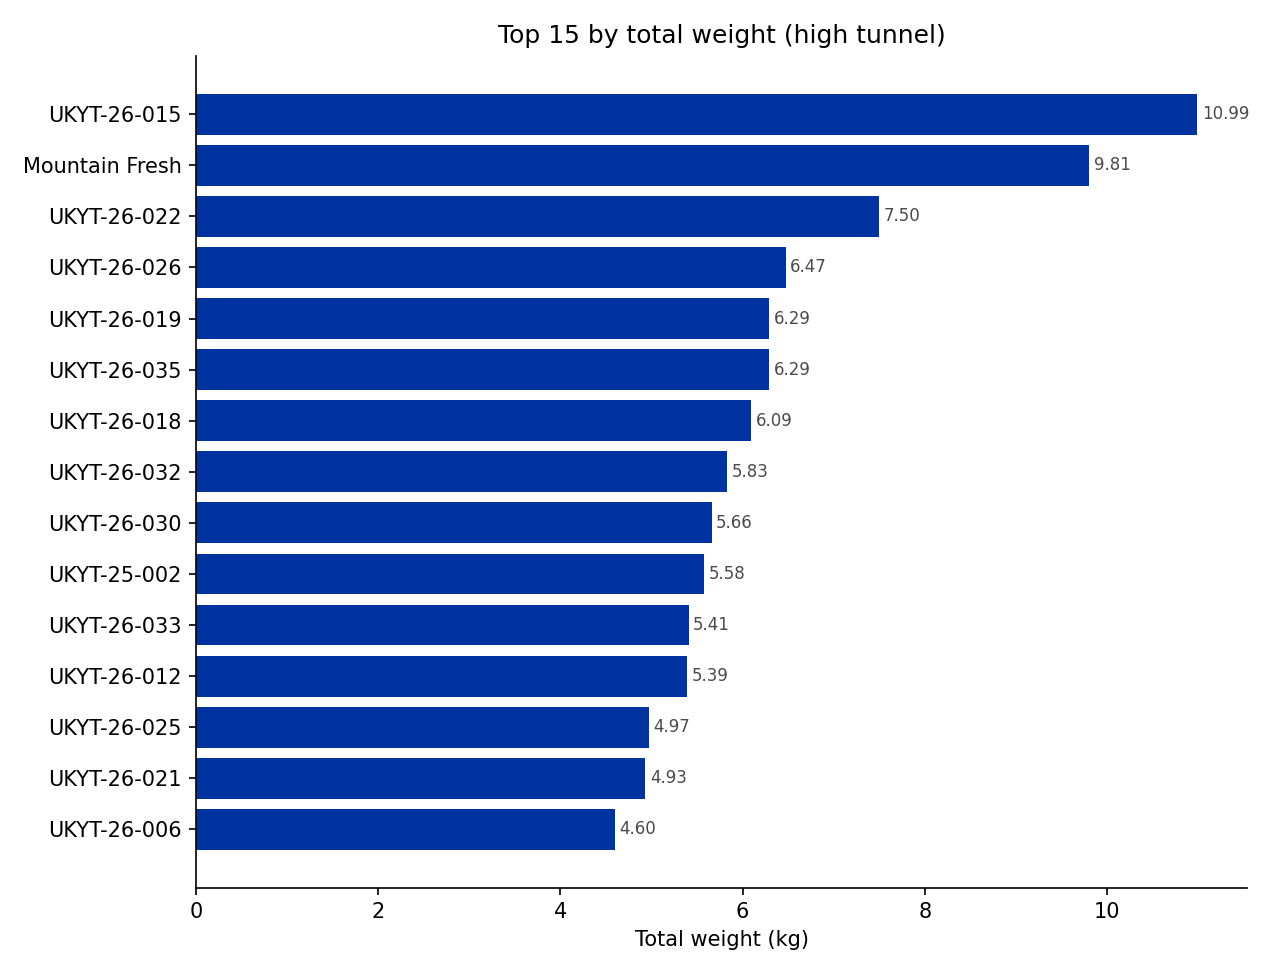

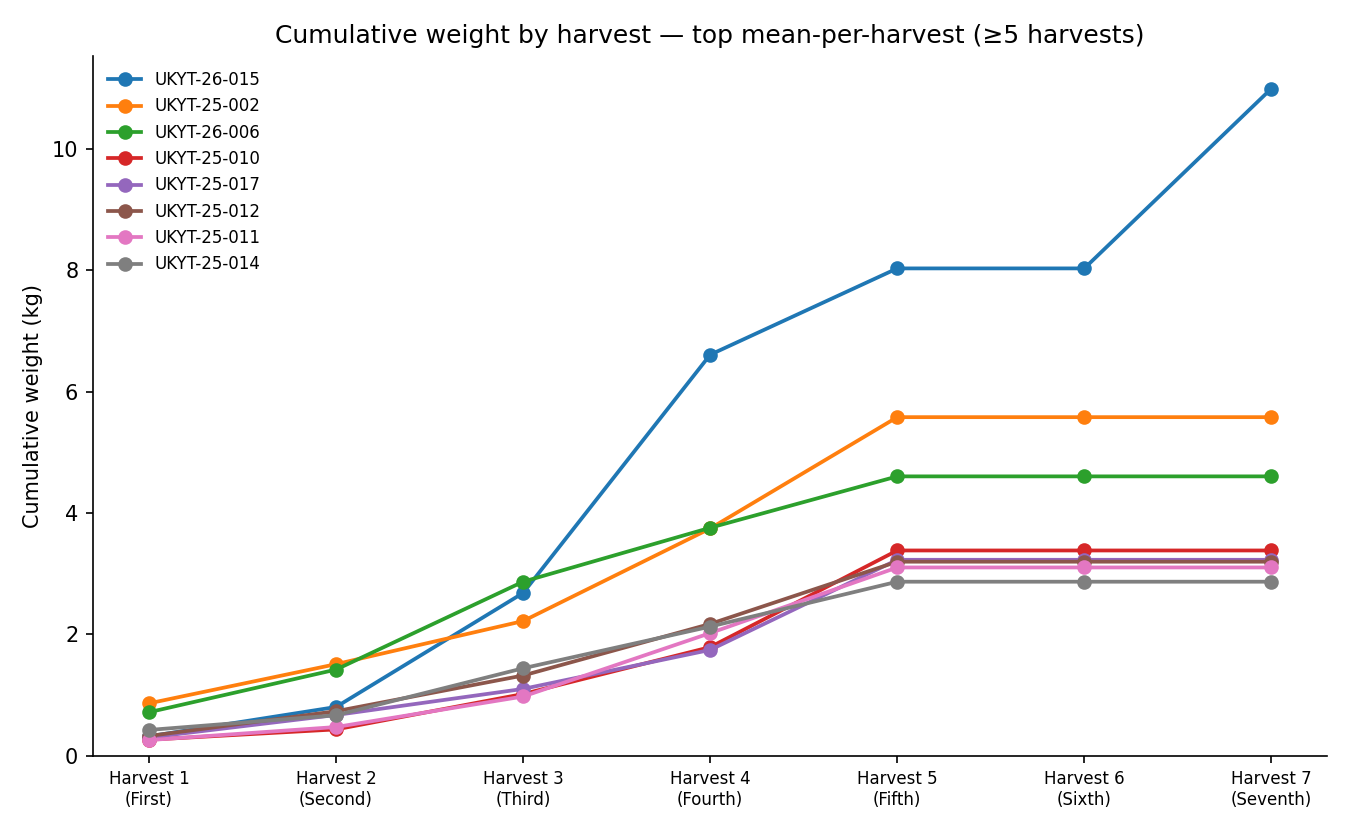

In [14]:
display(Image(filename="figures/fig1_top15_total_weight.png"))
display(Image(filename="figures/fig6_cumulative_weight_by_harvest.png"))